   
WarmUp
=======

Trend-Seasonal
=======
**Times series course**  
IMT Mines ALES  
2IA - 2022



## Dependencies

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import calendar
from pandas.plotting import autocorrelation_plot
from statsmodels.tsa.seasonal import seasonal_decompose

plt.rcParams['figure.figsize'] = [15, 5]

## Chickenpox

Create a panda data frame from the file `chickenpox.txt` and convert it to a panda dataframe. 

Set the index to time indexed monthly from 1931 to 1972 (you can use `pd.date_range`). 

In [4]:
df = pd.read_csv(
    "../data/chickenpox.txt",
    skiprows=1,
    header=None,
    names=["cases"],
)

# Build a monthly DatetimeIndex starting in January 1931.
# "MS" = month start; use periods=len(df) so the index always matches the data length.
df.index = pd.date_range(start="1931-01", periods=len(df), freq="MS")
df.index.name = "date"

print(df.index[-1])
df.head()

1972-06-01 00:00:00


,cases
date,
1931-01-01,956
1931-02-01,927
1931-03-01,1585
1931-04-01,1536
1931-05-01,1448


What is the average number of cases per month?

In [8]:
monthly_avg = df.groupby(df.index.month)['cases'].mean()
monthly_avg

date
1      891.904762
2     1015.047619
3     1386.261905
4     1427.380952
5     1294.404762
6     1055.166667
7      408.219512
8      131.975610
9       83.780488
10     147.609756
11     312.804878
12     569.073171
Name: cases, dtype: float64

<Axes: title={'center': 'Average chickenpox cases per month'}, ylabel='Average cases'>

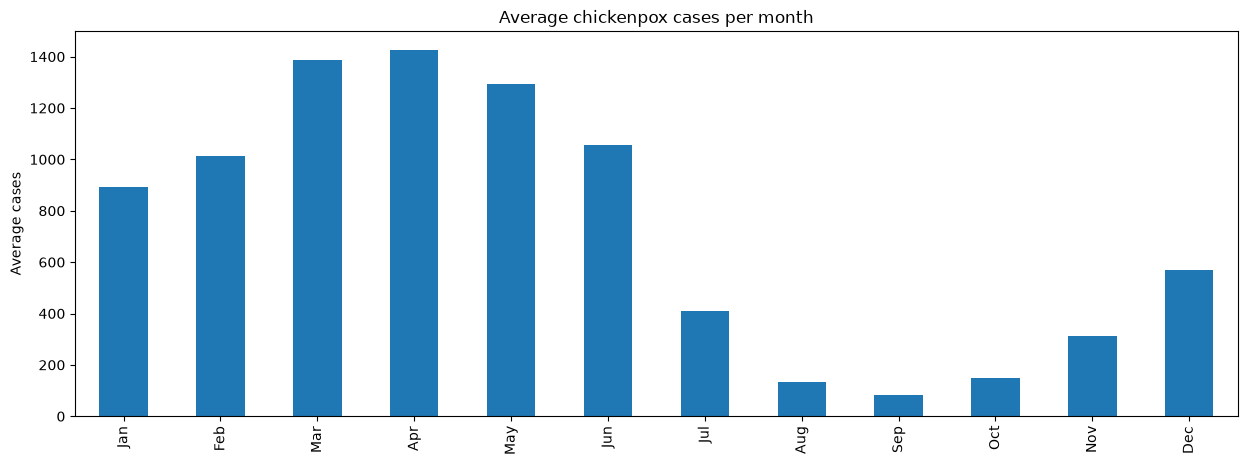

In [10]:
monthly_avg.index = [calendar.month_abbr[m] for m in monthly_avg.index]
monthly_avg.plot(kind="bar", ylabel="Average cases", title="Average chickenpox cases per month")

Compute the global trend of the number of cases for each year. Plot the result. Could you see any trend?

*(tip: you can `resample` the data)*

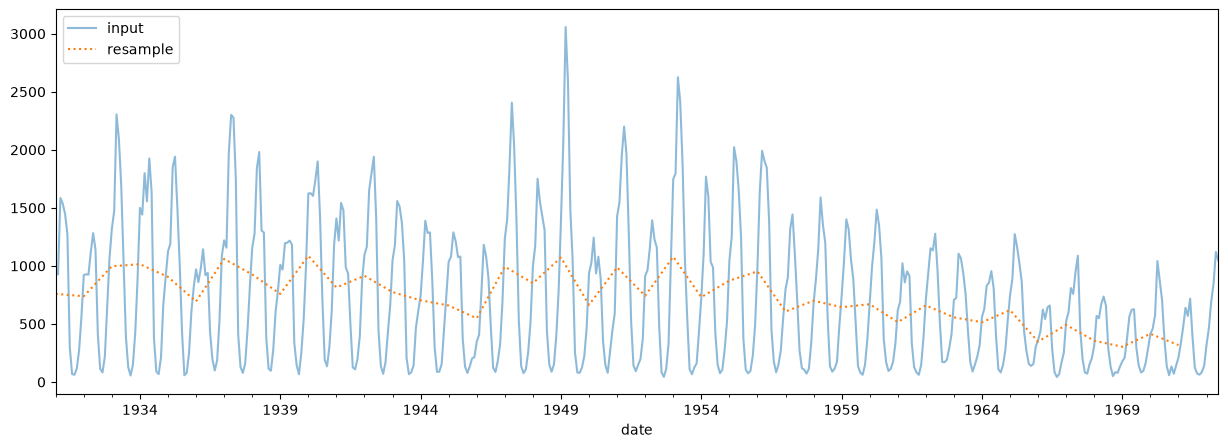

In [ ]:
cases = df["cases"]

yearly_avg = cases.resample("YS").mean()
# As 1972 goes until june, its statistics can distort the average. We will remove it.
yearly_avg = yearly_avg.loc[:"1971"]

fig, ax = plt.subplots()

cases.plot(ax=ax, alpha=0.5, style="-", label="input")
yearly_avg.plot(ax=ax, style=":", label="resample")

ax.legend(loc="upper left")
plt.show()

Could you see any seasonality on the full data? You can zoom in.

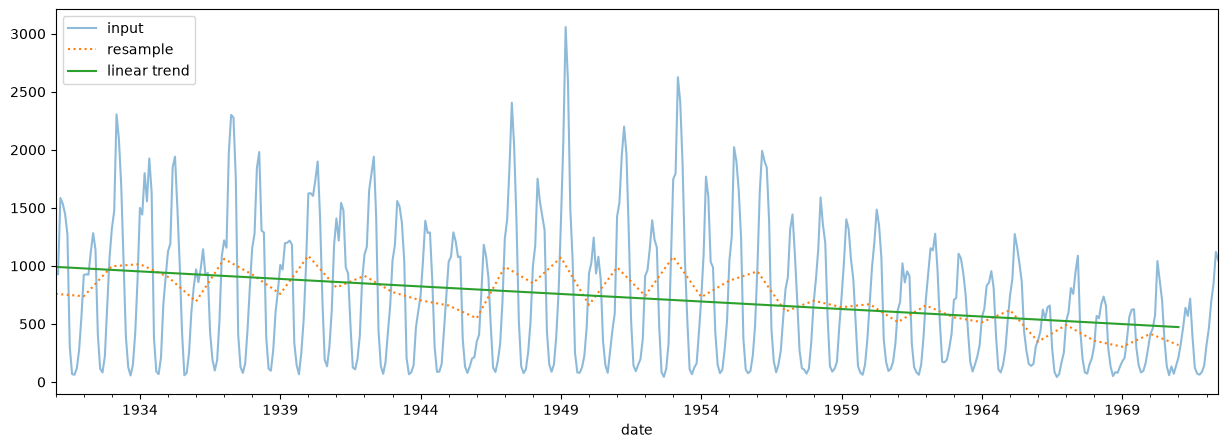

-13.0 cases/month per year


In [20]:
x = yearly_avg.index.year
y = yearly_avg.values

slope, intercept = np.polyfit(x, y, 1)
trend = pd.Series(slope * x + intercept, index=yearly_avg.index)

fig, ax = plt.subplots()

cases.plot(ax=ax, alpha=0.5, style="-", label="input")
yearly_avg.plot(ax=ax, style=":", label="resample")
trend.plot(ax=ax, label="linear trend")

ax.legend(loc="upper left")
plt.show()

print(f"{slope:.1f} cases/month per year")

Plot the autocorrelation function (you can use `autocorrelation_plot` from pandas).   
Interpret the results. What mean the dotted lines?

The ACF oscillates with a period of 12 lags: strong positive peaks at lags 12, 24, 36… and negative troughs at lags 6, 18, 30…, which reveals a strong yearly seasonality. The peaks decay very slowly, so the series is non-stationary (seasonality and trend). The dotted/solid horizontal lines are the 99%/95% confidence bands under the white-noise hypothesis (±z/√n). Almost every lag falls outside them, so the autocorrelations are significant. Lag 24 being higher than lag 12 also hints at a ~2-year cycle.

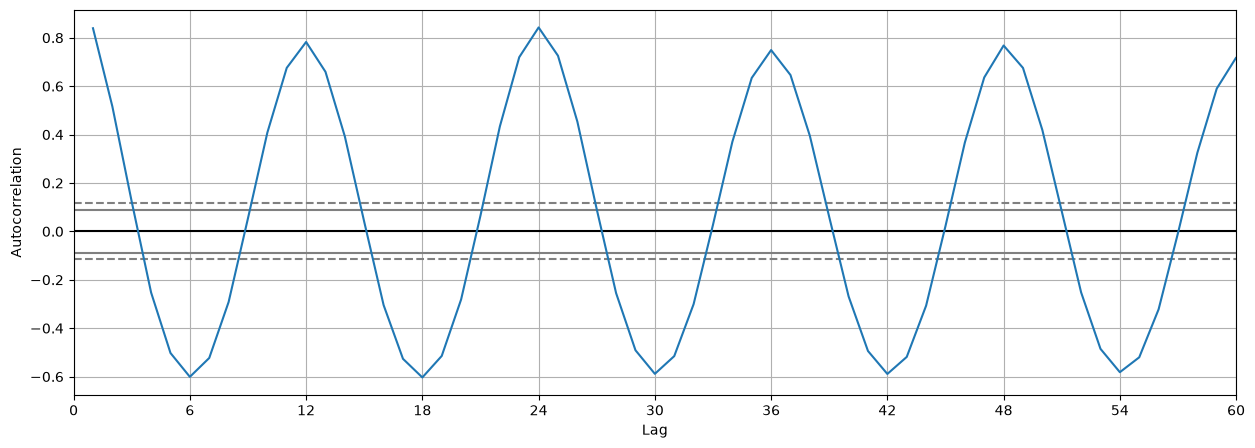

In [22]:
fig, ax = plt.subplots()
autocorrelation_plot(cases, ax=ax)
ax.set_xlim(0, 60)          # zoom on the first 5 years of lags
ax.set_xticks(range(0, 61, 6))
plt.show()

Plot on the same graph a twelve month's time series of each year.

*(tip: you could add columns for month and year in the dataframe, and then create a pivot table, that has one column for each year in the data set and one row for each day-of-year)*

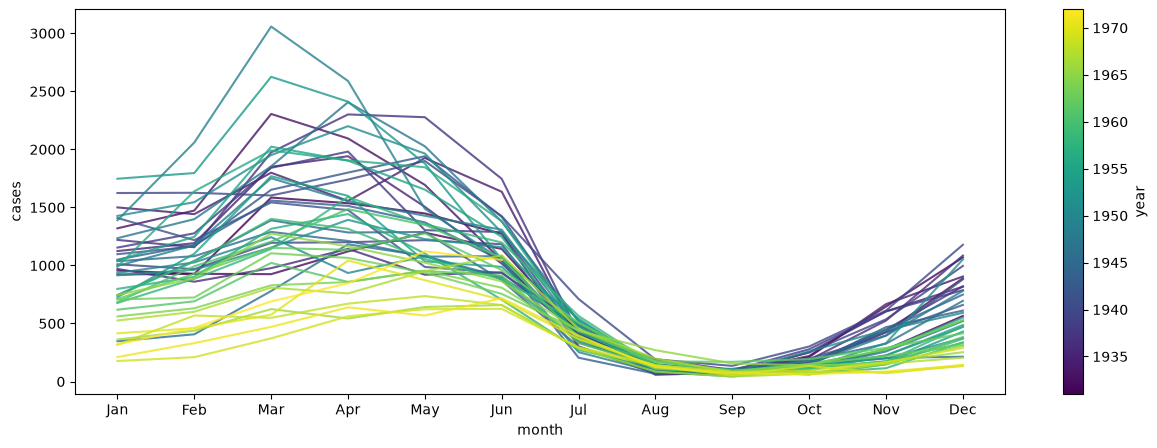

In [23]:
# Add calendar columns derived from the DatetimeIndex
df["year"] = df.index.year
df["month"] = df.index.month

# One row per month (1–12), one column per year
pivot = df.pivot_table(index="month", columns="year", values="cases")

# Color each year along a colormap so the time progression is readable
colors = plt.cm.viridis(np.linspace(0, 1, pivot.shape[1]))

fig, ax = plt.subplots()
pivot.plot(ax=ax, color=colors, legend=False, alpha=0.8)

# A colorbar replaces a 42-entry legend
sm = plt.cm.ScalarMappable(
    cmap="viridis",
    norm=plt.Normalize(pivot.columns.min(), pivot.columns.max()),
)
fig.colorbar(sm, ax=ax, label="year")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(calendar.month_abbr[1:])
ax.set_ylabel("cases")
plt.show()

Plot the global trend of the number of cases for each year.

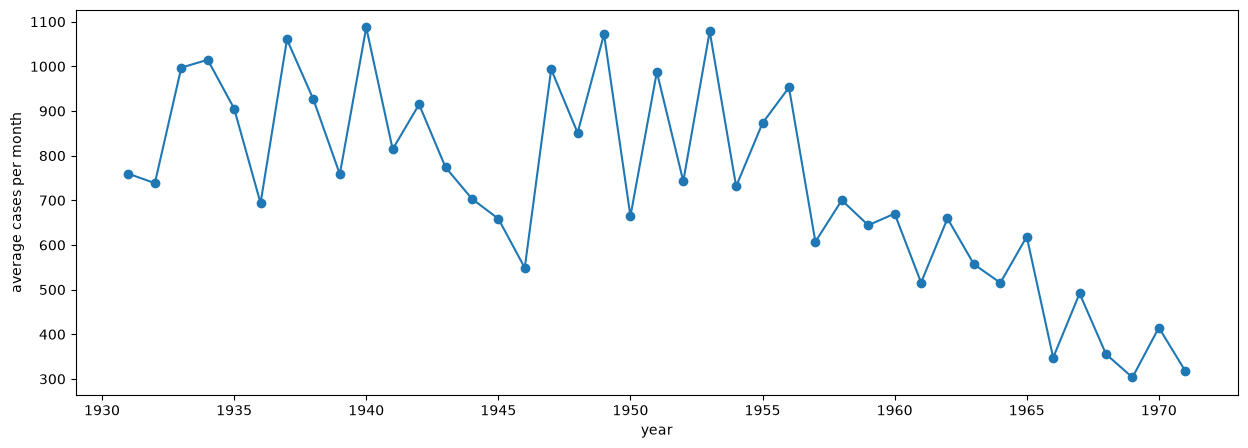

In [24]:
yearly_trend = pivot.drop(columns=1972).mean()   # mean over the 12 months of each year

fig, ax = plt.subplots()
yearly_trend.plot(ax=ax, marker="o")
ax.set_xlabel("year")
ax.set_ylabel("average cases per month")
plt.show()

## Analyse trend and seasonal with built in functions

Plot a seasonal decomposition using moving averages. You can use the `statsmodels` toolbox. Is there a specific time where the model does not fit well the data?

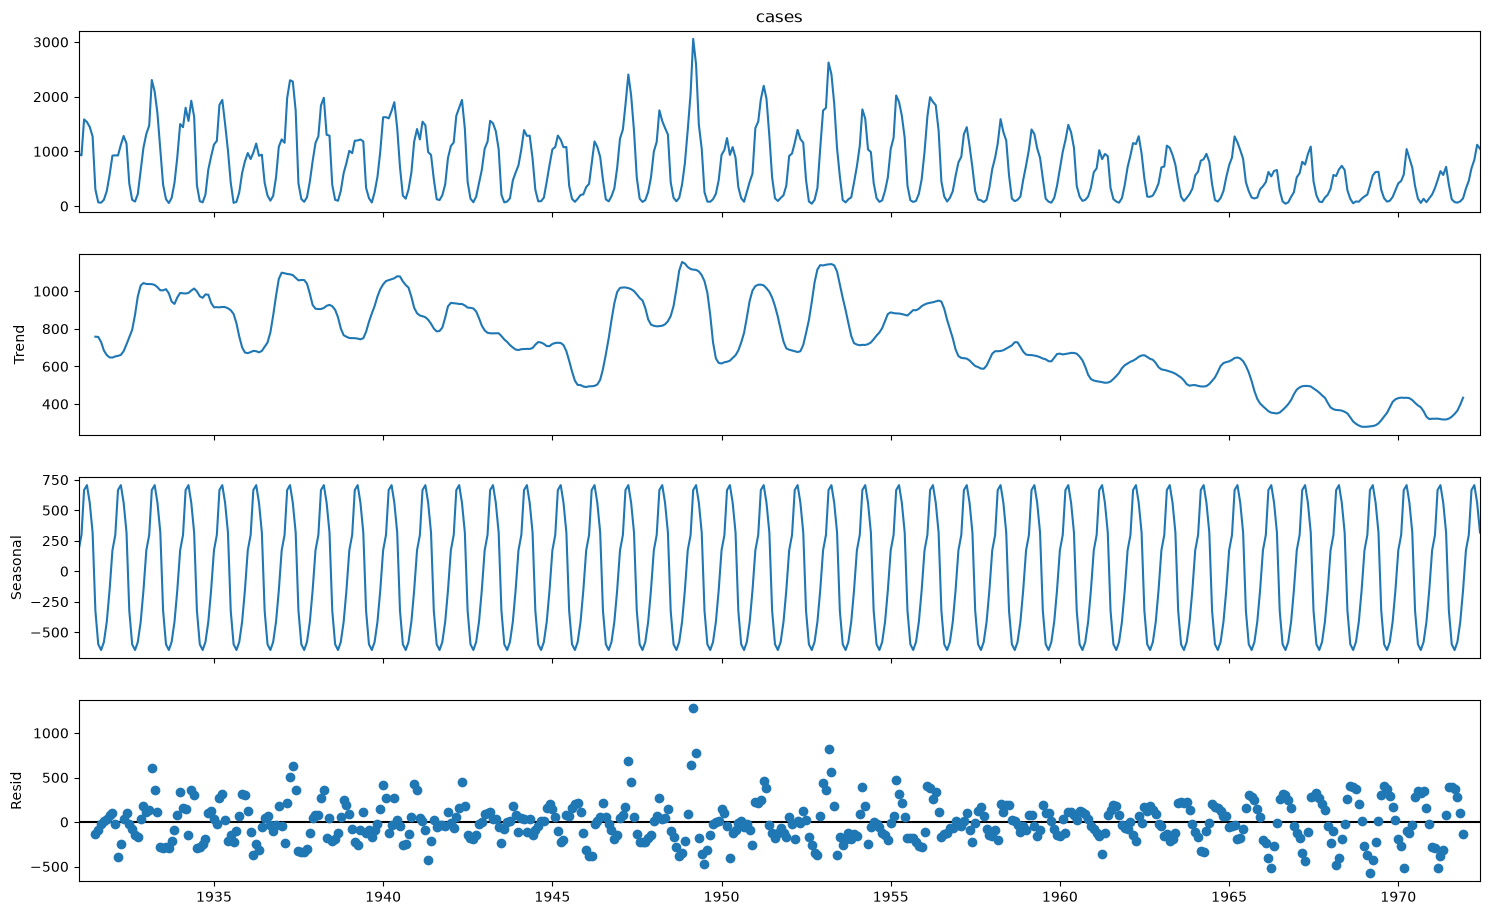

In [26]:
decomposition = seasonal_decompose(cases, model="additive", period=12)

fig = decomposition.plot()
fig.set_size_inches(15, 10)
plt.show()

In [27]:
resid = decomposition.resid.dropna()
resid.abs().sort_values(ascending=False).head(10)

date
1949-03-01    1277.925277
1953-03-01     816.925277
1949-04-01     769.863819
1947-04-01     683.655486
1949-02-01     643.299236
1937-05-01     629.595069
1933-03-01     602.133611
1969-03-01     574.324723
1953-04-01     560.988819
1970-03-01     522.116389
Name: resid, dtype: float64

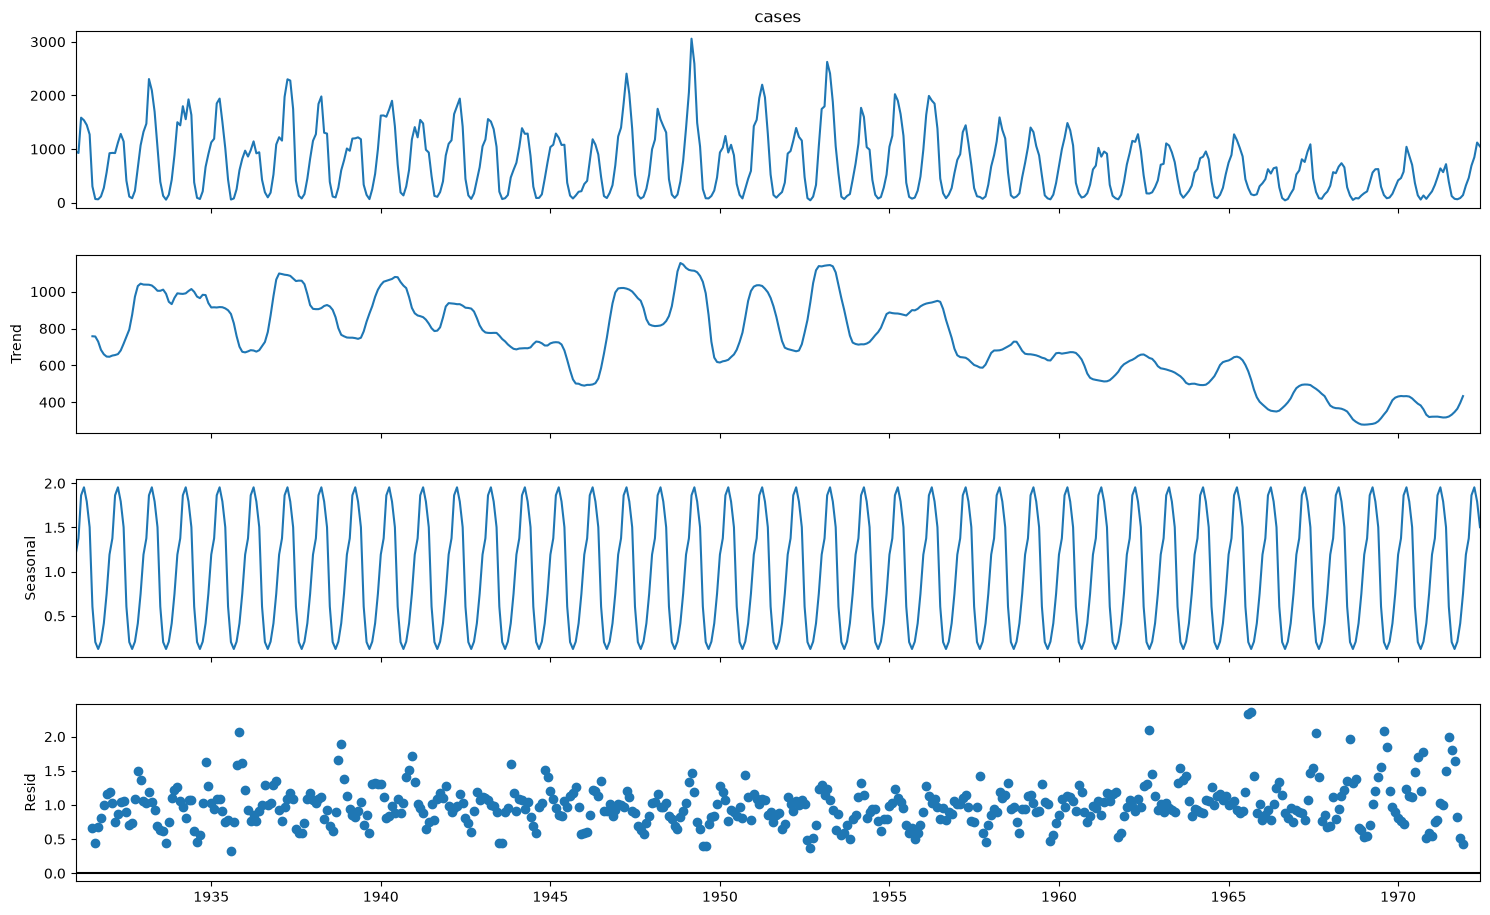

date
1965-09-01    1.365366
1965-08-01    1.326070
1962-09-01    1.101643
1969-08-01    1.081986
1935-11-01    1.068950
1967-08-01    1.049438
1971-07-01    1.000592
1968-08-01    0.962326
1938-11-01    0.891886
1969-09-01    0.840898
Name: resid, dtype: float64

In [28]:
# Multiplicative: seasonal amplitude scales with the trend level (justified by the earlier analysis)
decomposition_mul = seasonal_decompose(cases, model="multiplicative", period=12)
fig = decomposition_mul.plot()
fig.set_size_inches(15, 10)
plt.show()

# Residuals are ratios here: 1 = perfect fit, so rank by distance from 1
resid_mul = decomposition_mul.resid.dropna()
(resid_mul - 1).abs().sort_values(ascending=False).head(10)